# Prédire les feux de forêt en Tunisie : comparaison de modèles de Machine Learning

**Question :** à partir de la météo d'une journée, peut-on prédire s'il y aura un feu dans une forêt tunisienne ?

Ce notebook présente le jeu de données (construit à partir des satellites de la NASA et de la météo ERA5) puis compare
**6 familles d'algorithmes** et **2 références** avec une **validation croisée imbriquée groupée par année**.

> Les modèles sont entraînés par `run_experiments.py` et les figures produites par `make_figures.py`.
> Ce notebook relit les résultats enregistrés dans `reports/` pour les analyser.

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd
from IPython.display import Image, display

from src.data import load_clean, ZONES, ALL_FEATURES
from src.fwi import ffmc_step, dmc_step, dc_step, isi_calc, bui_calc, fwi_calc

pd.set_option("display.precision", 3)
RES, FIG = "../reports/results/", "../reports/figures/"
show = lambda name: display(Image(filename=FIG + name))

## 1. Les données

Deux sources publiques croisées pour **7 zones forestières**, chaque jour du 1er juin au 30 septembre, 2013–2025 :
- **NASA FIRMS** (satellite VIIRS, 375 m) : un jour-zone est « avec feu » si un feu de végétation de confiance moyenne/haute
  est détecté à moins de 25 km du centre de la zone ;
- **Open-Meteo / ERA5** : température max., humidité min., vent max., pluie du jour.

Les 6 indices du système canadien **FWI** sont calculés à partir de la météo par `src/fwi.py`.

In [2]:
pd.DataFrame(ZONES, columns=['zone', 'gouvernorat', 'latitude', 'longitude'])

,zone,gouvernorat,latitude,longitude
0,Aïn Draham,Jendouba,36.78,8.69
1,Nefza,Béja,36.95,9.08
2,Sejnane,Bizerte,37.06,9.24
3,Kesra,Siliana,35.85,9.30
4,Le Kef,Le Kef,36.20,8.70
5,Cap Bon,Nabeul,36.95,10.95
6,Chaambi,Kasserine,35.20,8.65


In [3]:
df = load_clean(save=False)
print(df.shape, f"— {df.fire.mean():.1%} de jours avec feu")
df.head()

(11102, 18) — 10.4% de jours avec feu


,date,year,month,zone,governorate,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,n_detections,frp_total,fire
0,2013-06-01,2013,6,Aïn Draham,Jendouba,15.5,70,27.9,2.3,72.94,26.61,179.25,2.83,38.81,7.06,0,0.0,0
1,2013-06-02,2013,6,Aïn Draham,Jendouba,17.6,47,21.5,0.0,84.32,29.22,185.82,5.68,41.94,13.29,0,0.0,0
2,2013-06-03,2013,6,Aïn Draham,Jendouba,18.7,49,17.3,0.0,86.71,31.87,192.59,6.40,45.09,15.17,0,0.0,0
3,2013-06-04,2013,6,Aïn Draham,Jendouba,18.4,52,13.5,0.0,86.78,34.34,199.31,5.34,48.00,13.65,0,0.0,0
4,2013-06-05,2013,6,Aïn Draham,Jendouba,23.9,42,16.2,0.0,89.08,38.16,207.01,8.50,52.24,20.24,0,0.0,0


### Vérification du calcul FWI sur l'exemple de référence officiel (Van Wagner)

In [4]:
# Jour d'avril : 17 °C, 42 % d'humidité, vent 25 km/h, pas de pluie, valeurs de départ standard
f = ffmc_step(85, 17, 42, 25, 0); d = dmc_step(6, 17, 42, 0, 4); c = dc_step(15, 17, 0, 4)
i = isi_calc(f, 25); b = bui_calc(d, c)
print("obtenu  :", [round(v, 2) for v in (f, d, c, i, b, fwi_calc(i, b))])
print("attendu : [87.69, 8.55, 19.01, 10.85, 8.49, 10.1]")

obtenu  : [87.69, 8.55, 19.01, 10.85, 8.49, 10.1]
attendu : [87.69, 8.55, 19.01, 10.85, 8.49, 10.1]


In [5]:
df.groupby(['zone', 'governorate'])['fire'].agg(jours_feu='sum', taux='mean').sort_values('jours_feu', ascending=False)

,,jours_feu,taux
zone,governorate,,
Le Kef,Le Kef,244,0.154
Nefza,Béja,209,0.132
Sejnane,Bizerte,203,0.128
Chaambi,Kasserine,186,0.117
Aïn Draham,Jendouba,185,0.117
Cap Bon,Nabeul,67,0.042
Kesra,Siliana,66,0.042


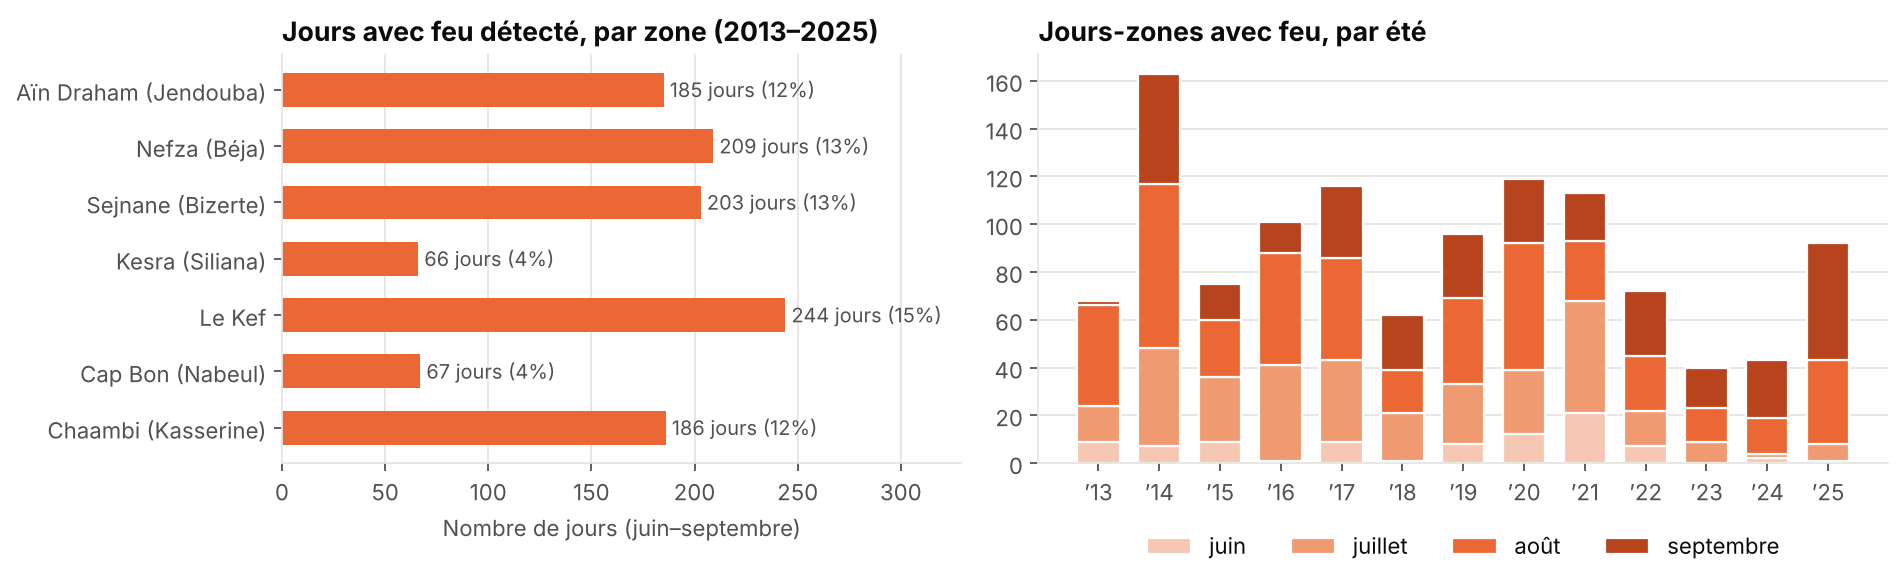

In [6]:
show('01_feux_par_zone_et_annee.png')

## 2. Exploration

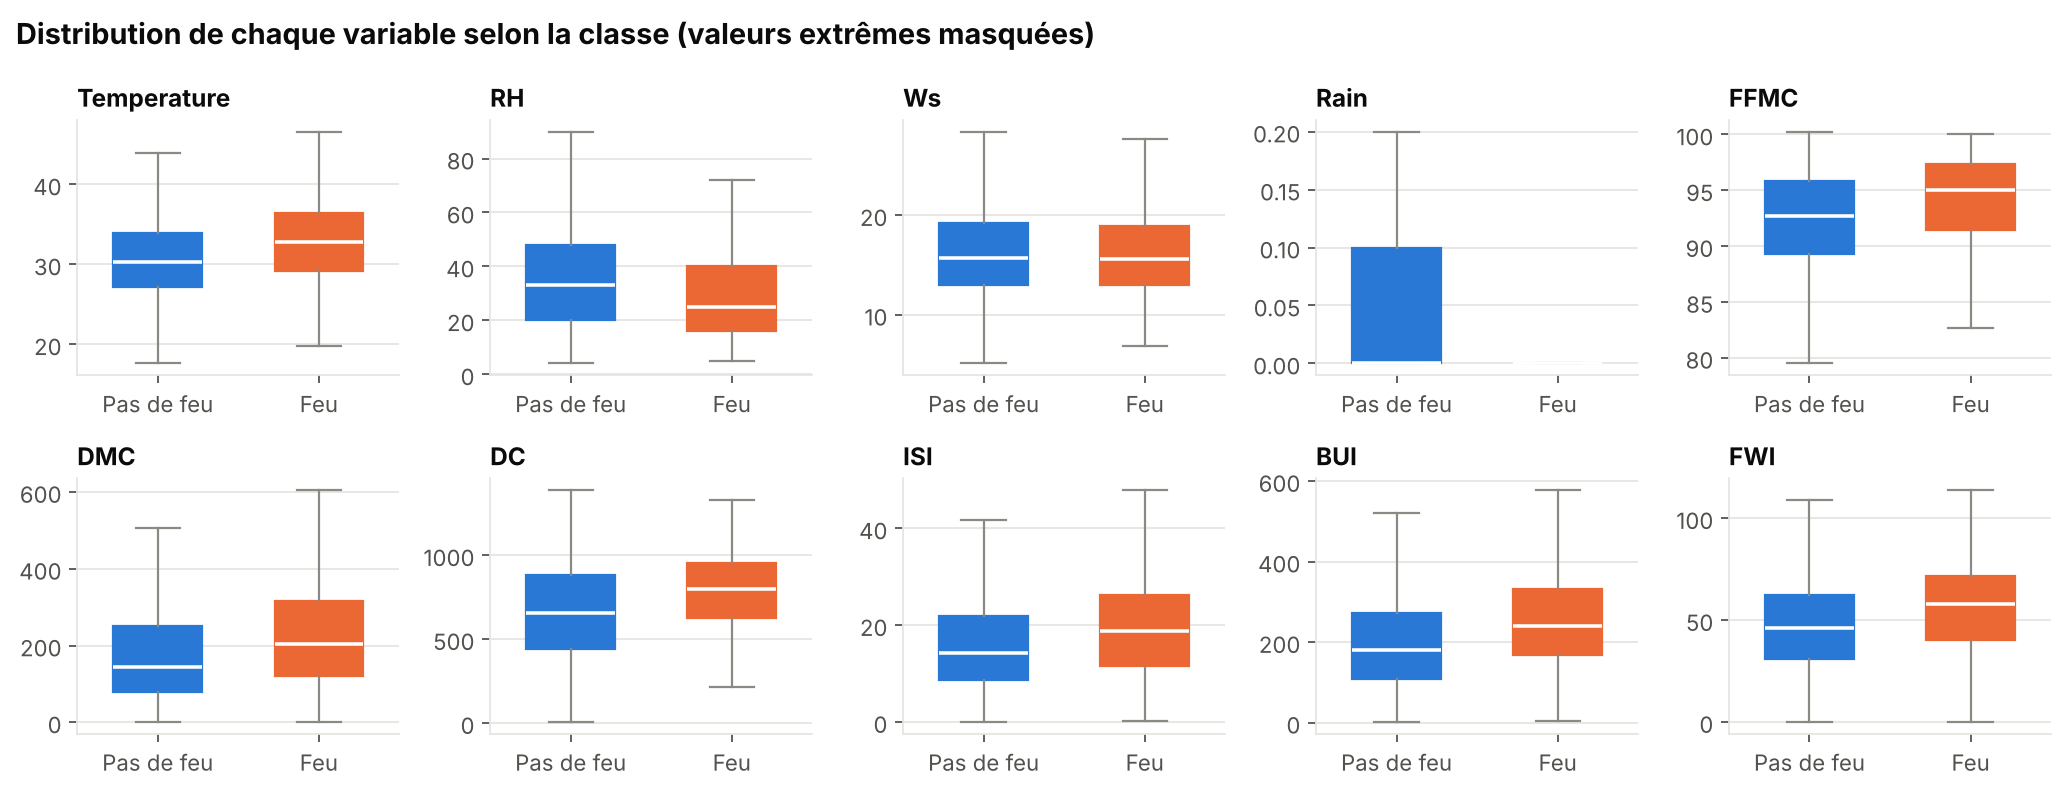

In [7]:
show('02_distributions_par_classe.png')

Les jours de feu sont plus chauds, plus secs, et surtout plus avancés dans la saison sèche (codes `DC` et `BUI` élevés).
Mais **les deux classes se chevauchent largement** : la météo seule ne peut pas tout expliquer.

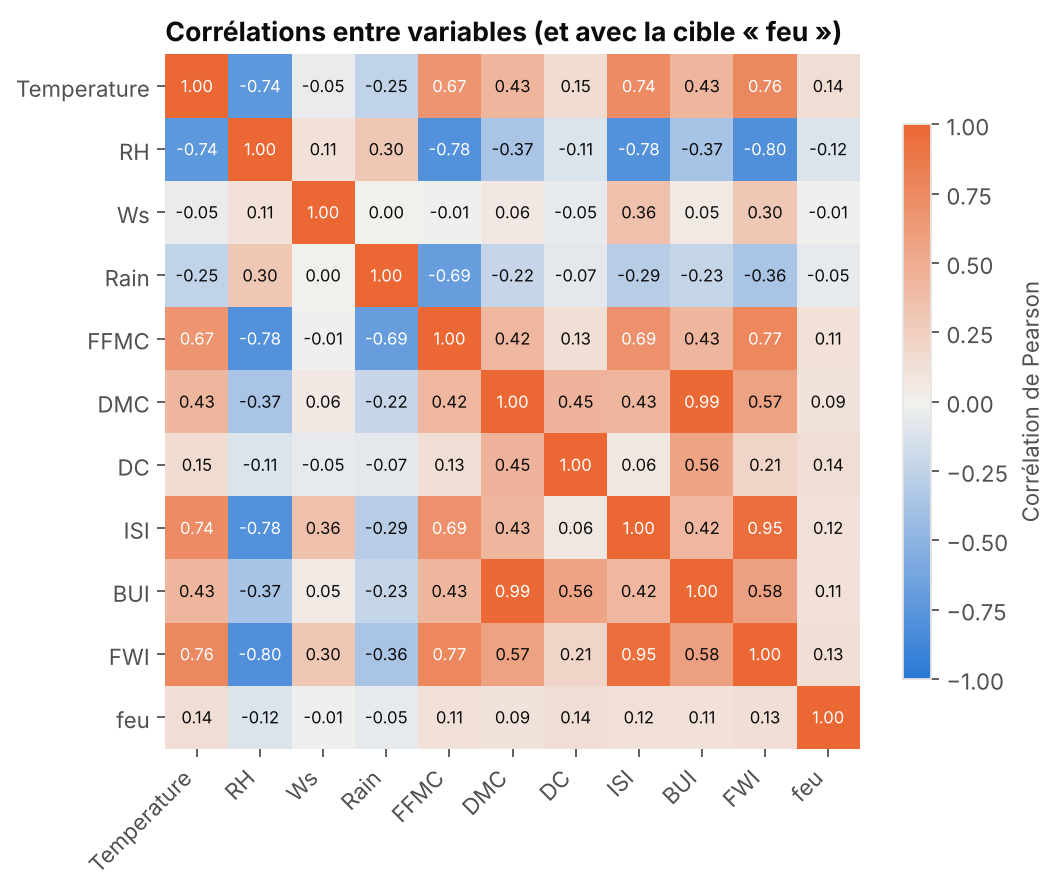

In [8]:
show('04_correlations.png')

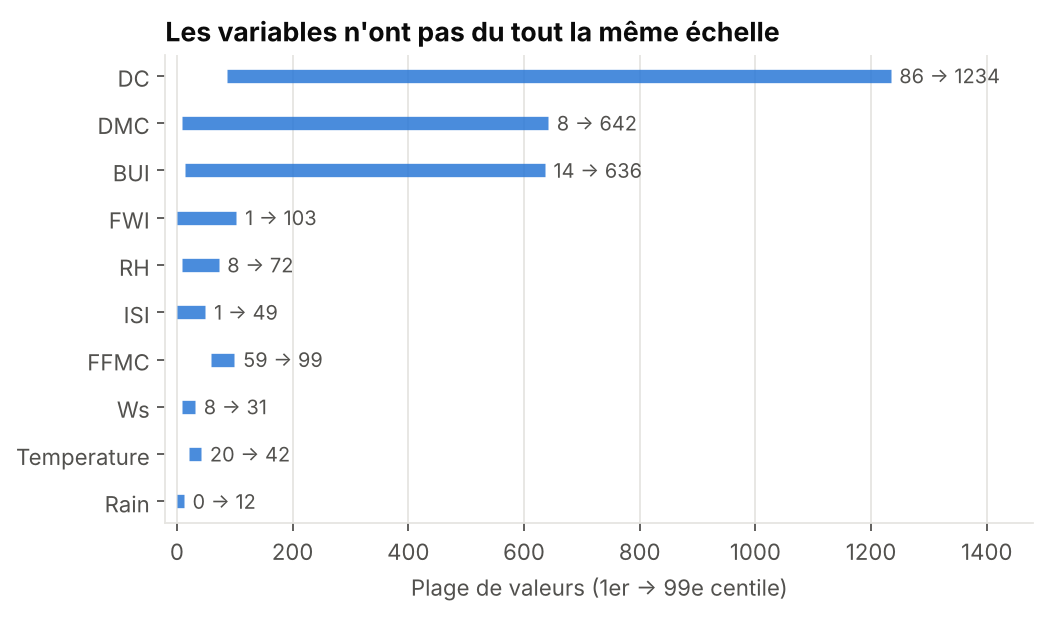

In [9]:
show('03_echelles_des_variables.png')

## 3. Protocole

| Famille | Modèle | Classes rares |
|---|---|---|
| Référence | Hasard / indice FWI officiel seul | — |
| Linéaire | Régression logistique | pondérées |
| Basé sur les instances | k-NN | impossible |
| Arbres | Arbre de décision | pondérées |
| Ensemble (bagging) | Random Forest | pondérées |
| Ensemble (boosting) | Gradient Boosting | pondérées |
| Méthodes à noyau | SVM (RBF) | pondérées |

- **Validation croisée imbriquée groupée par année** : externe 5 plis × 3 répétitions, interne 3 plis. Un été de test n'est
  jamais vu à l'entraînement ni au réglage.
- **Métrique principale : précision moyenne** (aire sous la courbe précision-rappel). Le hasard vaut 0,104.
- **Test de Student corrigé** (Nadeau & Bengio, 2003) pour les écarts.

## 4. Résultats

In [10]:
summary = pd.read_csv(RES + "cv_summary.csv")
cols = ["model", "family", "average_precision_mean", "average_precision_std", "roc_auc_mean", "recall_mean", "f1_mean", "fit_time_mean"]
table = lambda fs: summary[summary.features == fs][cols].sort_values("average_precision_mean", ascending=False).reset_index(drop=True)
pd.concat([table("meteo+FWI"), table("FWI seul")], ignore_index=True)

,model,family,average_precision_mean,average_precision_std,roc_auc_mean,recall_mean,f1_mean,fit_time_mean
0,Random Forest,Ensemble (bagging),0.199,0.055,0.690,0.586,0.280,10.282
1,Gradient Boosting,Ensemble (boosting),0.197,0.052,0.696,0.698,0.273,3.617
2,Régression logistique,Linéaire,0.191,0.043,0.684,0.678,0.265,0.289
3,k-NN,Basé sur les instances,0.187,0.036,0.671,0.000,0.000,1.744
4,SVM (noyau RBF),Méthodes à noyau,0.179,0.041,0.680,0.672,0.268,8.220
5,Arbre de décision,Arbres,0.166,0.034,0.654,0.640,0.243,0.297
6,Baseline (au hasard),Référence,0.104,0.012,0.500,0.000,0.000,0.002
7,Indice FWI officiel seul,Référence,0.182,0.052,0.647,0.608,0.241,0.006


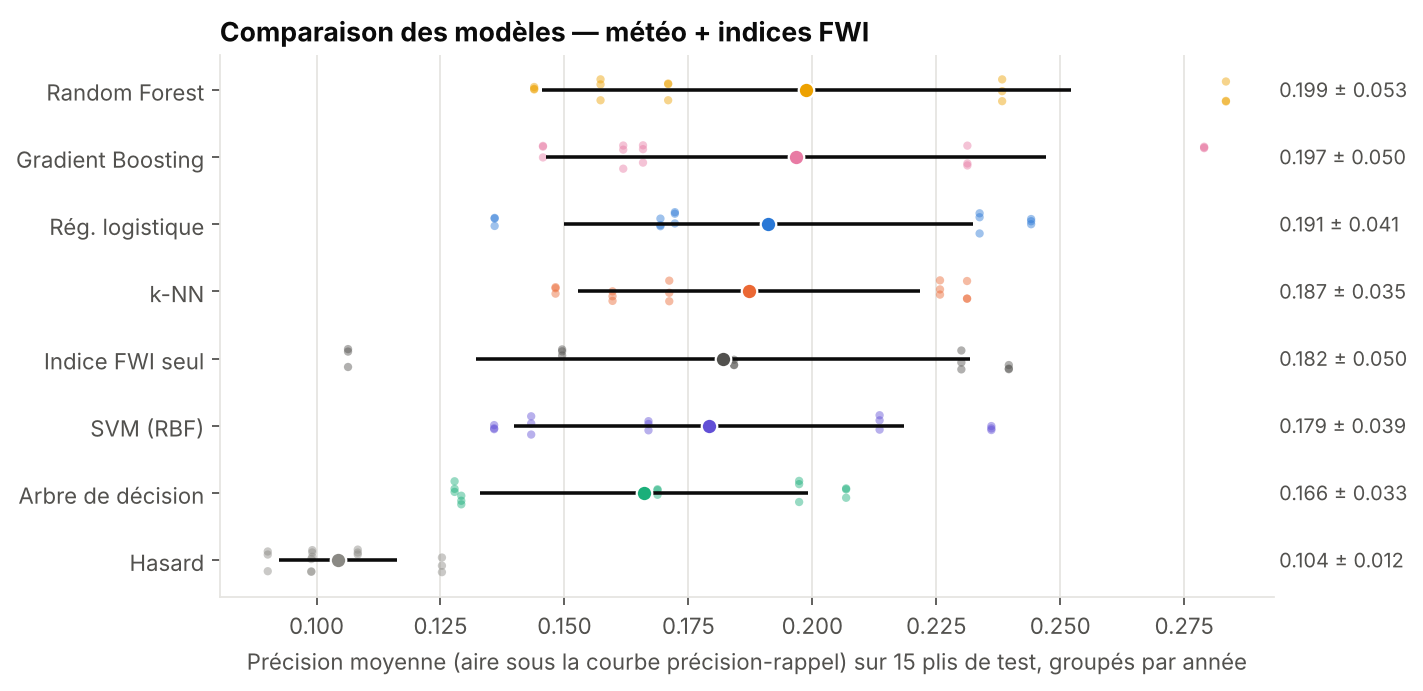

In [11]:
show('05_comparaison_modeles.png')

In [12]:
tests = pd.read_csv(RES + "significance_tests.csv")
tests[tests.features == "meteo+FWI"][["best", "other", "delta", "p_value"]]

,best,other,delta,p_value
0,Random Forest,Gradient Boosting,0.002,0.445
1,Random Forest,Régression logistique,0.008,0.565
2,Random Forest,k-NN,0.012,0.435
3,Random Forest,SVM (noyau RBF),0.020,0.301
4,Random Forest,Arbre de décision,0.033,0.045
5,Random Forest,Baseline (au hasard),0.094,0.006
6,Random Forest,Indice FWI officiel seul,0.017,0.493


Avec les indices FWI, **Random Forest est en tête mais à égalité statistique** avec Gradient Boosting, la régression logistique,
le k-NN, le SVM et même l'indice FWI seul (p > 0,05). Seul l'arbre de décision unique est significativement derrière.

In [13]:
table('meteo seule')

,model,family,average_precision_mean,average_precision_std,roc_auc_mean,recall_mean,f1_mean,fit_time_mean
0,Random Forest,Ensemble (bagging),0.176,0.034,0.639,0.561,0.227,6.237
1,Régression logistique,Linéaire,0.172,0.040,0.641,0.610,0.234,0.093
2,Gradient Boosting,Ensemble (boosting),0.170,0.034,0.633,0.573,0.230,1.391
3,k-NN,Basé sur les instances,0.157,0.024,0.616,0.000,0.000,0.779
4,SVM (noyau RBF),Méthodes à noyau,0.157,0.027,0.623,0.626,0.225,8.574
5,Arbre de décision,Arbres,0.156,0.026,0.614,0.586,0.223,0.144
6,Baseline (au hasard),Référence,0.104,0.012,0.500,0.000,0.000,0.002


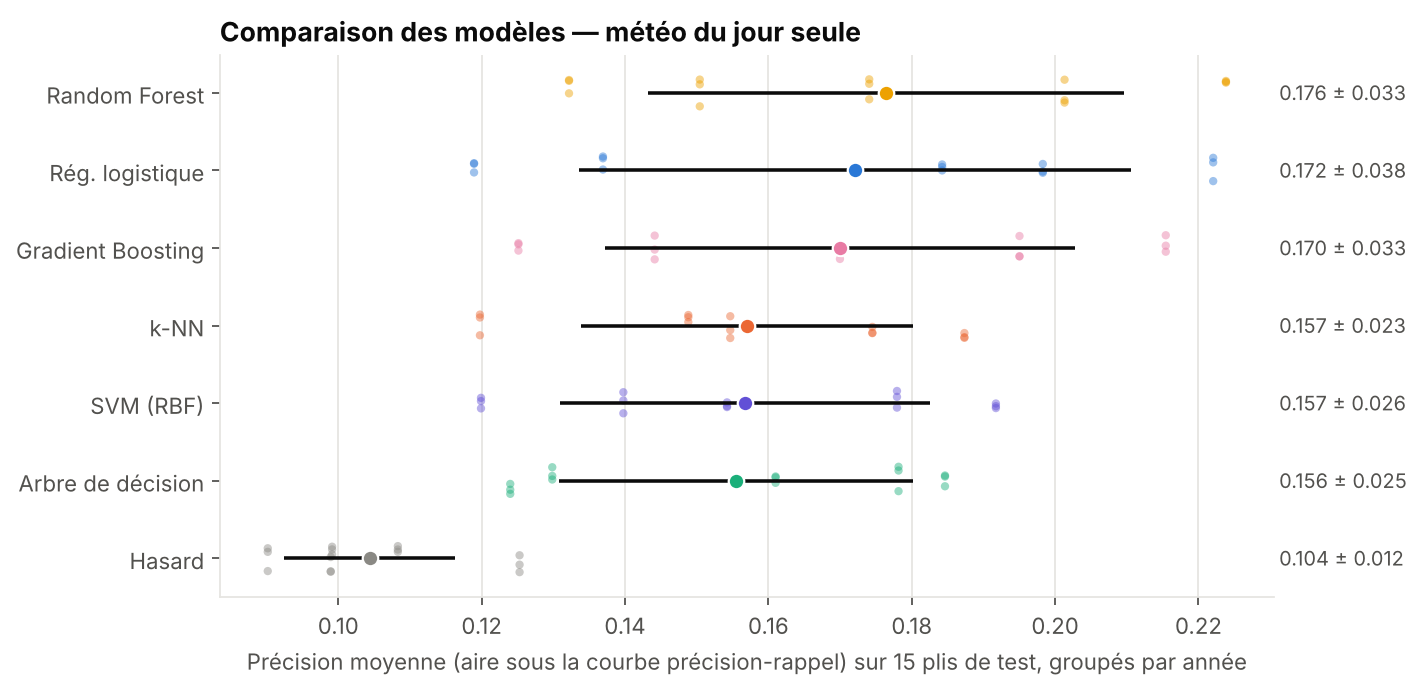

In [14]:
show('05b_comparaison_modeles_meteo_seule.png')

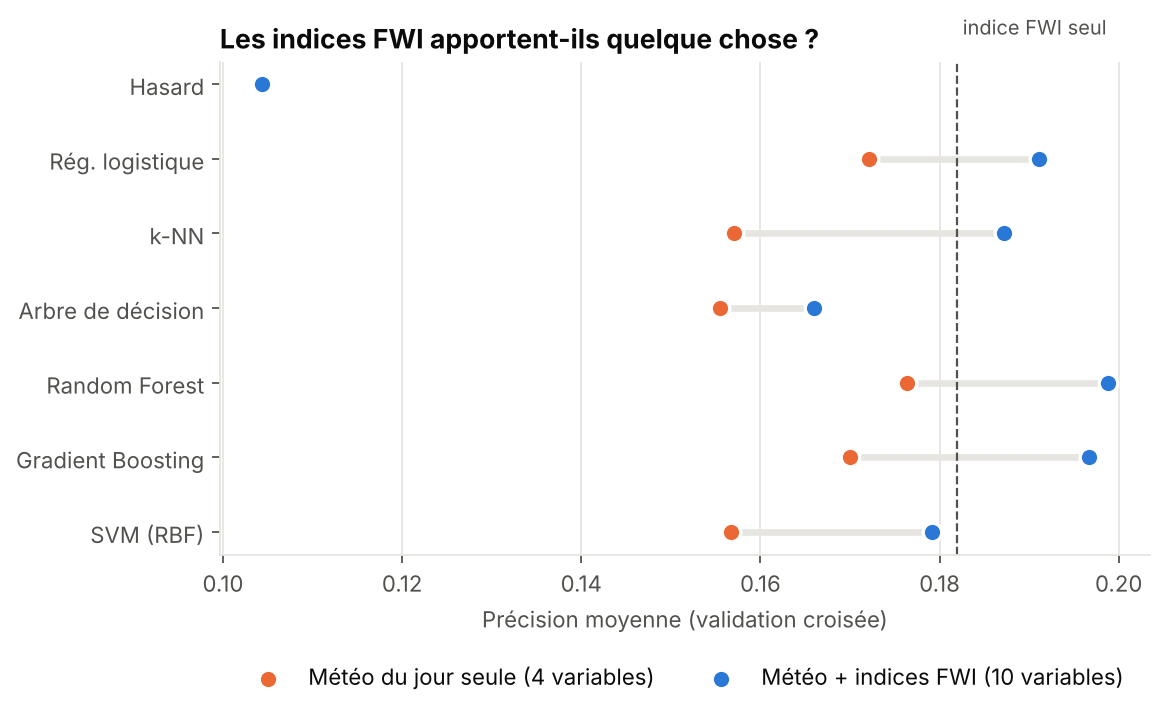

In [15]:
show('06_meteo_seule_vs_fwi.png')

## 5. Le piège de la fuite temporelle

In [16]:
leak = pd.read_csv(RES + "leakage_shuffled_cv.csv")
grp = summary[summary.features == "meteo+FWI"].set_index("model").average_precision_mean
leak["ap_grouped"] = leak.model.map(grp)
leak["gain_illusoire"] = (leak.ap_shuffled - leak.ap_grouped) / leak.ap_grouped
leak

,model,ap_shuffled,roc_auc_shuffled,ap_grouped,gain_illusoire
0,Baseline (au hasard),0.104,0.500,0.104,0.001
1,Régression logistique,0.182,0.686,0.191,-0.046
2,k-NN,0.231,0.716,0.187,0.231
3,Arbre de décision,0.185,0.691,0.166,0.115
4,Random Forest,0.222,0.724,0.199,0.116
5,Gradient Boosting,0.215,0.721,0.197,0.092
6,SVM (noyau RBF),0.207,0.719,0.179,0.155


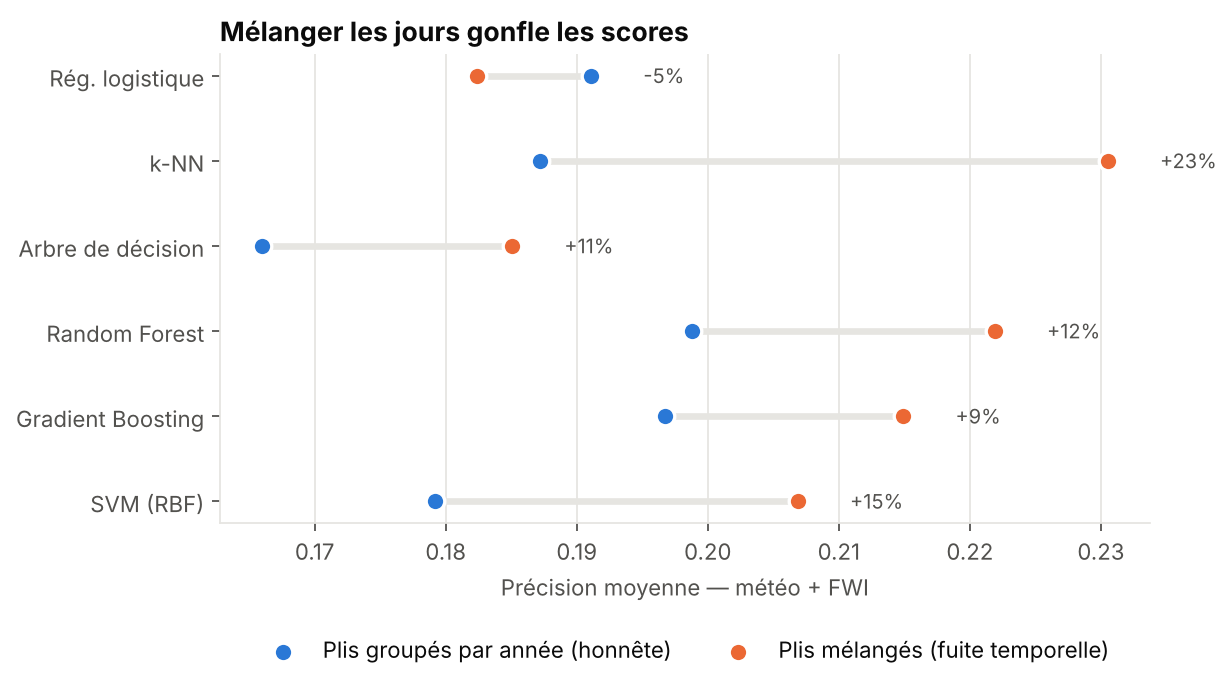

In [17]:
show('09c_fuite_temporelle.png')

## 6. La mise à l'échelle compte-t-elle ?

In [18]:
pd.read_csv(RES + 'scaling.csv').pivot_table(index='model', columns=['features', 'scaler'], values='ap_mean')

features              meteo seule                 meteo+FWI                
scaler                     aucune minmax standard    aucune minmax standard
model                                                                      
Arbre de décision           0.156  0.155    0.156     0.166  0.166    0.166
Gradient Boosting           0.170  0.170    0.170     0.197  0.197    0.197
Random Forest               0.176  0.176    0.176     0.199  0.199    0.199
Régression logistique       0.170  0.174    0.172     0.183  0.194    0.191
SVM (noyau RBF)             0.166  0.160    0.157     0.187  0.187    0.179
k-NN                        0.157  0.155    0.157     0.169  0.188    0.187

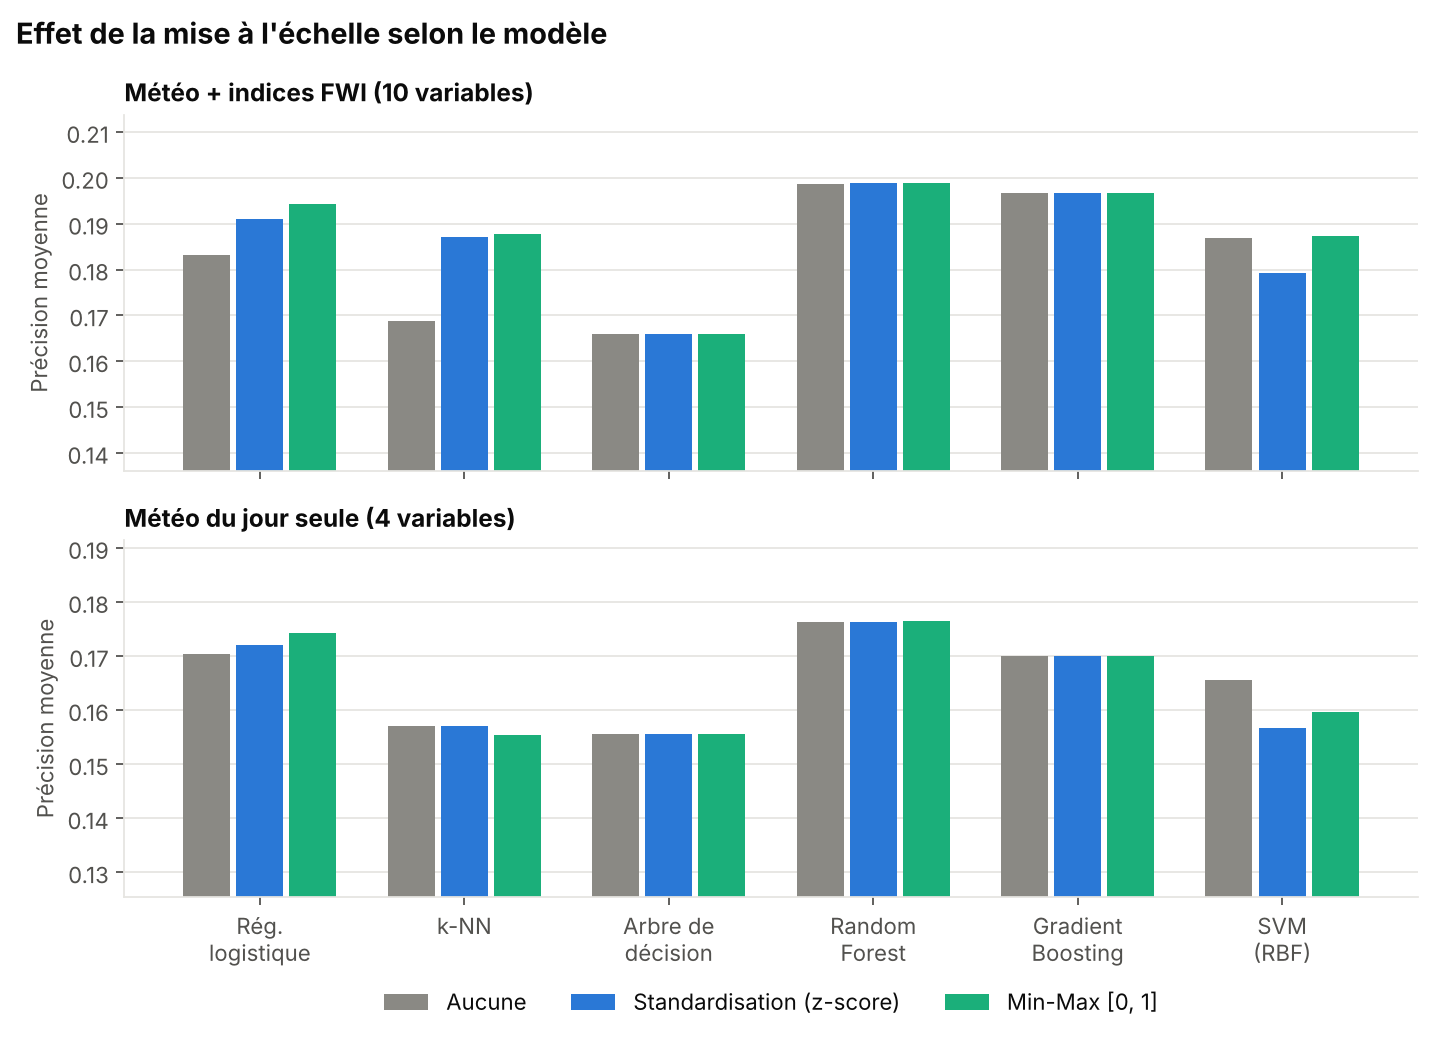

In [19]:
show('07_effet_mise_a_echelle.png')

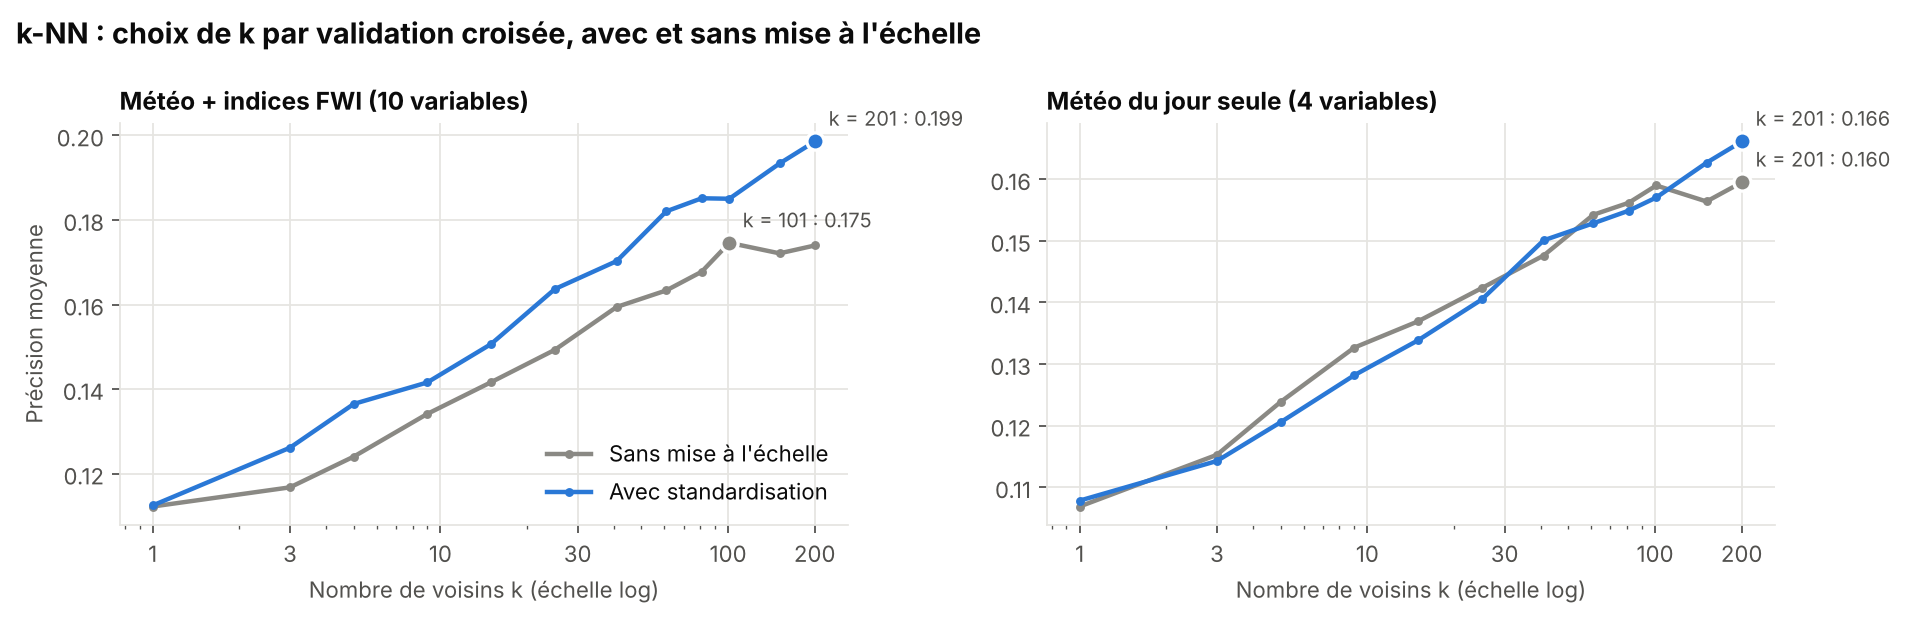

In [20]:
show('08_knn_choix_de_k.png')

## 7. Généralisation : une zone jamais vue, des étés futurs

In [21]:
loz = pd.read_csv(RES + "leave_one_zone_out.csv")
loz[loz.features == "meteo+FWI"].pivot_table(index="model", columns="test_zone", values="roc_auc")

test_zone,Aïn Draham,Cap Bon,Chaambi,Kesra,Le Kef,Nefza,Sejnane
model,,,,,,,
Arbre de décision,0.707,0.599,0.609,0.671,0.662,0.685,0.727
Baseline (au hasard),0.500,0.500,0.500,0.500,0.500,0.500,0.500
Gradient Boosting,0.727,0.602,0.635,0.697,0.695,0.683,0.740
Indice FWI officiel seul,0.700,0.587,0.704,0.595,0.569,0.534,0.624
Random Forest,0.732,0.589,0.631,0.689,0.699,0.691,0.735
Régression logistique,0.717,0.631,0.594,0.672,0.678,0.674,0.732
SVM (noyau RBF),0.716,0.583,0.653,0.674,0.681,0.712,0.753
k-NN,0.690,0.566,0.648,0.651,0.654,0.673,0.751


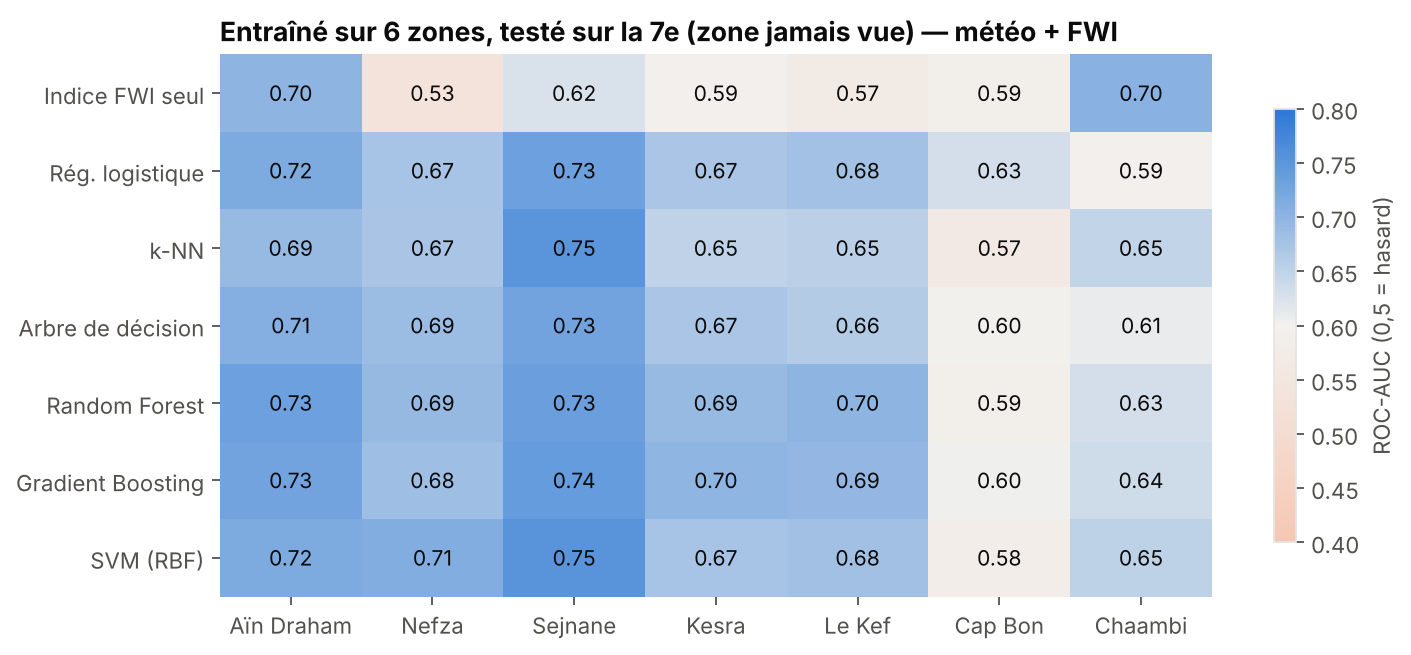

In [22]:
show('09_generalisation_zone_inconnue.png')

In [23]:
pd.read_csv(RES + 'temporal_split.csv')[['features', 'model', 'average_precision', 'roc_auc', 'recall']]

,features,model,average_precision,roc_auc,recall
0,meteo+FWI,Baseline (au hasard),0.072,0.500,0.000
1,meteo+FWI,Régression logistique,0.096,0.612,0.632
2,meteo+FWI,k-NN,0.092,0.595,0.000
3,meteo+FWI,Arbre de décision,0.097,0.631,0.538
4,meteo+FWI,Random Forest,0.094,0.614,0.417
5,meteo+FWI,Gradient Boosting,0.093,0.626,0.664
6,meteo+FWI,SVM (noyau RBF),0.103,0.630,0.619
7,meteo+FWI,Indice FWI officiel seul,0.076,0.514,0.538
8,meteo seule,Baseline (au hasard),0.072,0.500,0.000
9,meteo seule,Régression logistique,0.083,0.546,0.607


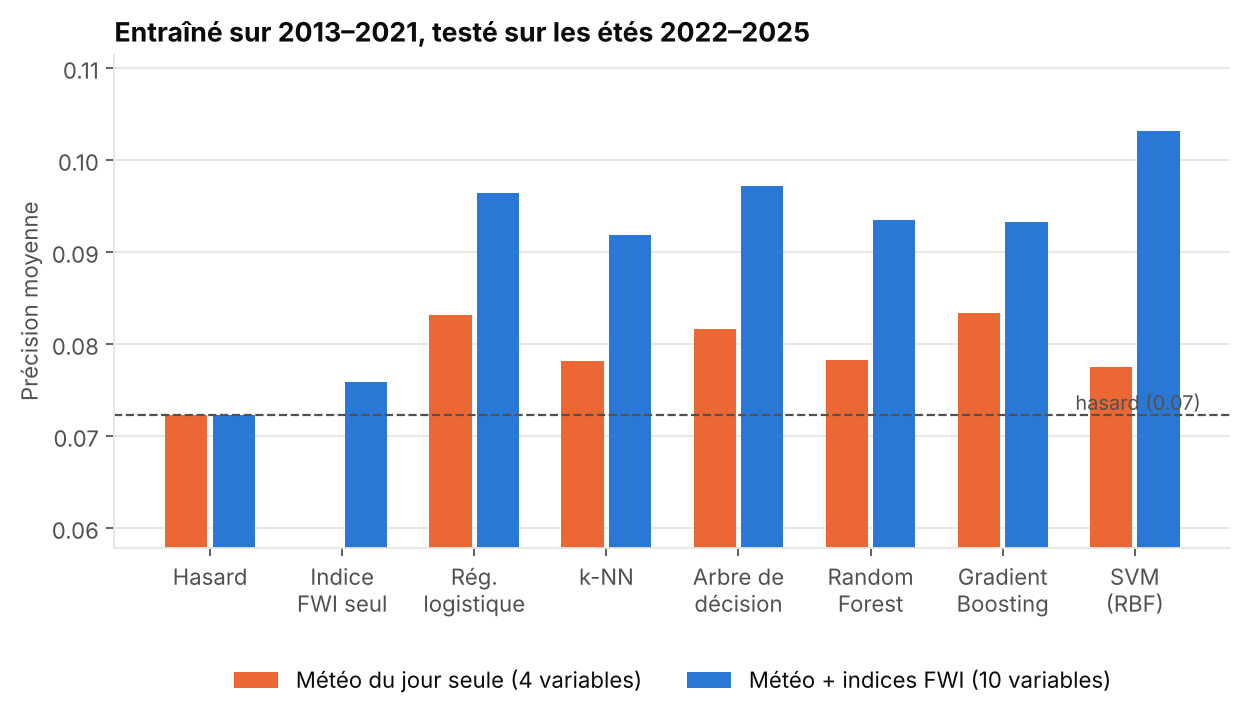

In [24]:
show('09b_generalisation_temporelle.png')

## 8. Erreurs et variables importantes

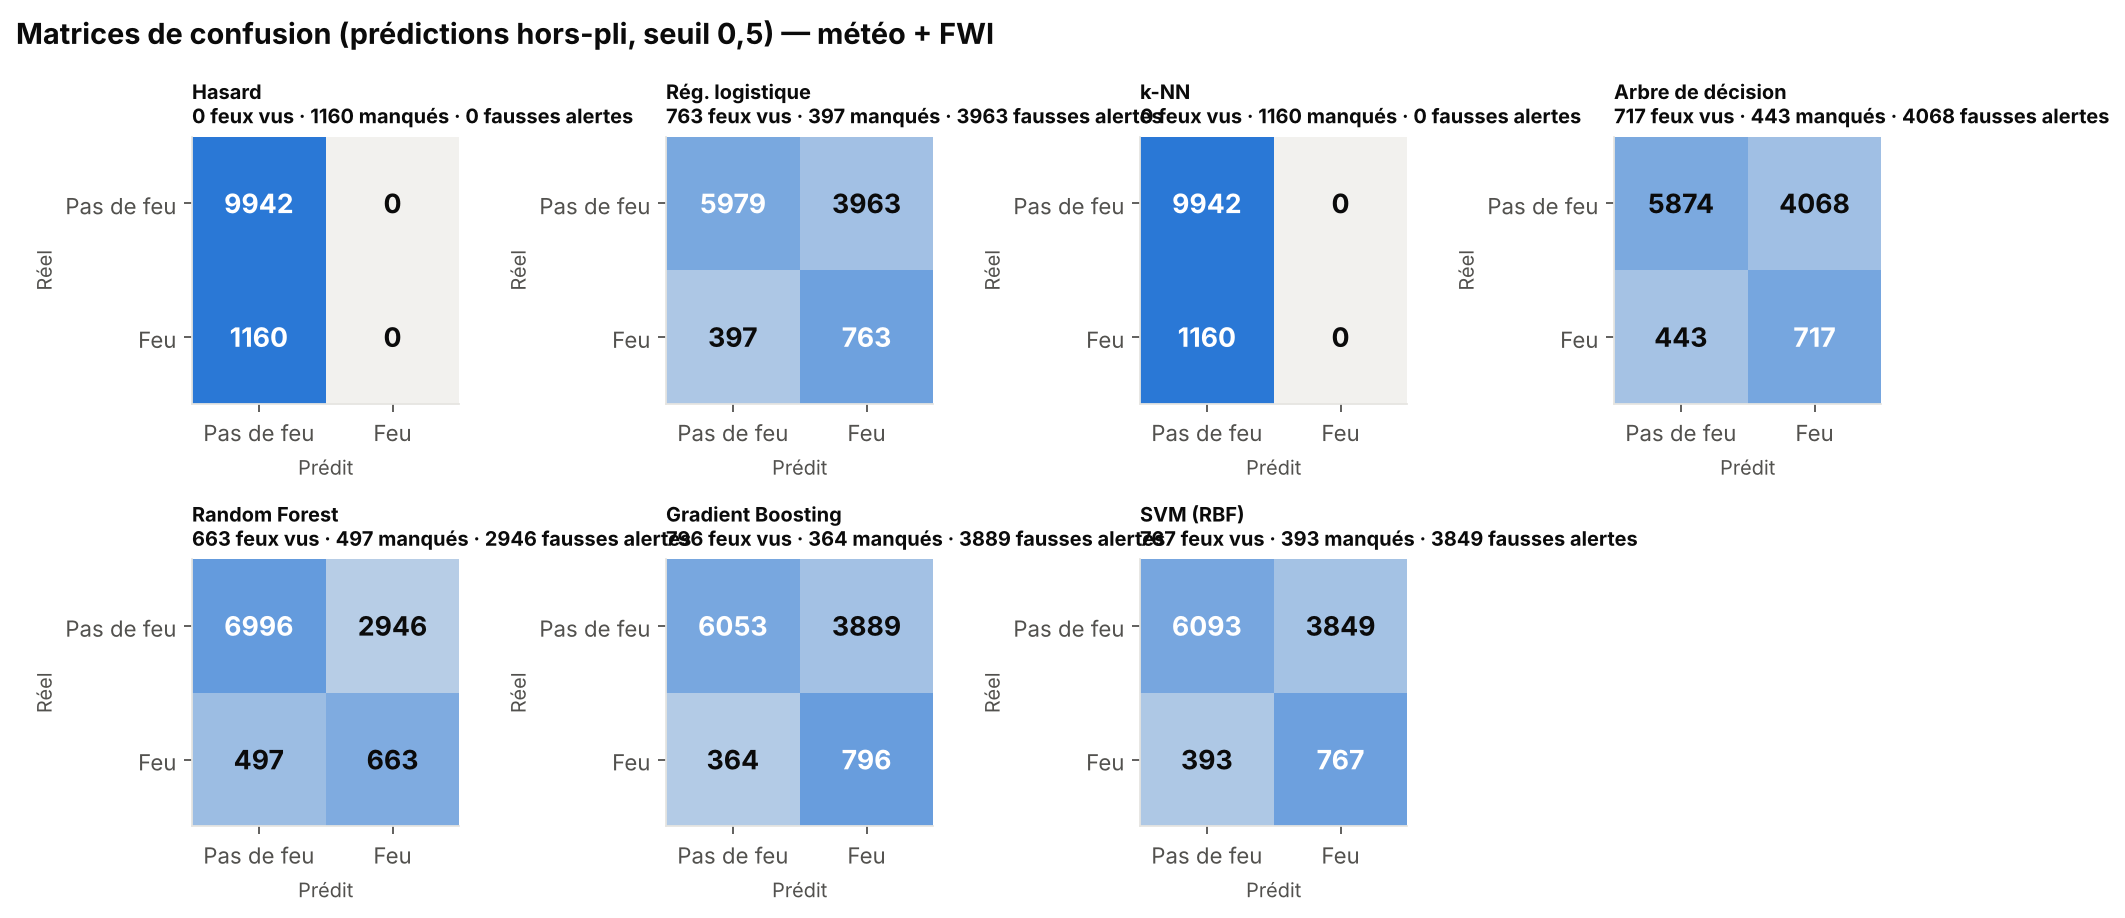

In [25]:
show('10_matrices_confusion.png')

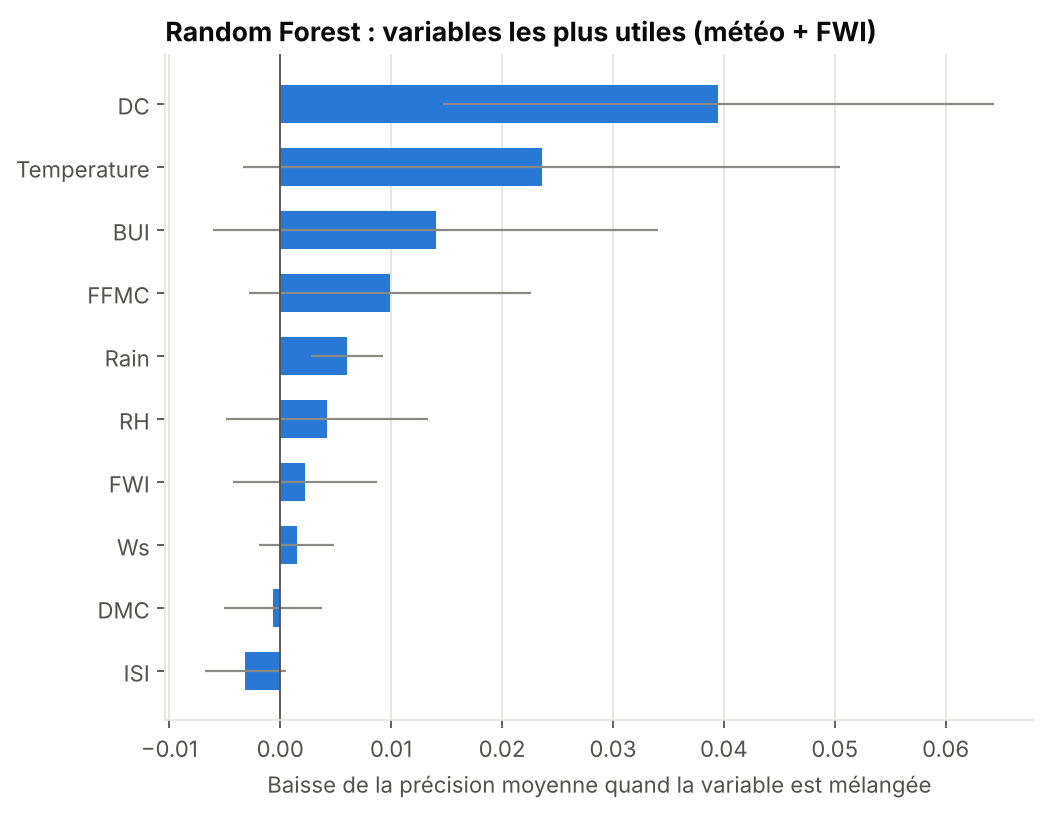

In [26]:
show('11_importance_variables.png')

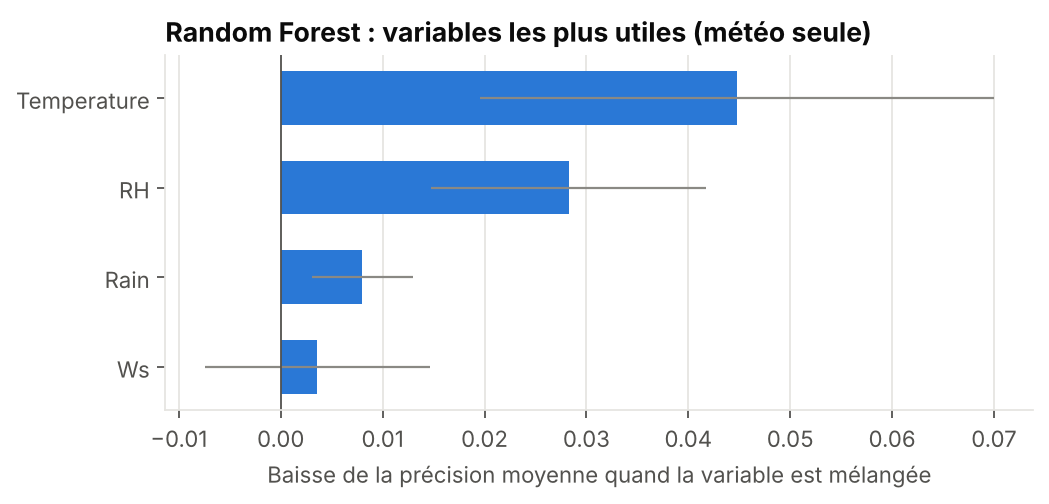

In [27]:
show('11b_importance_meteo_seule.png')

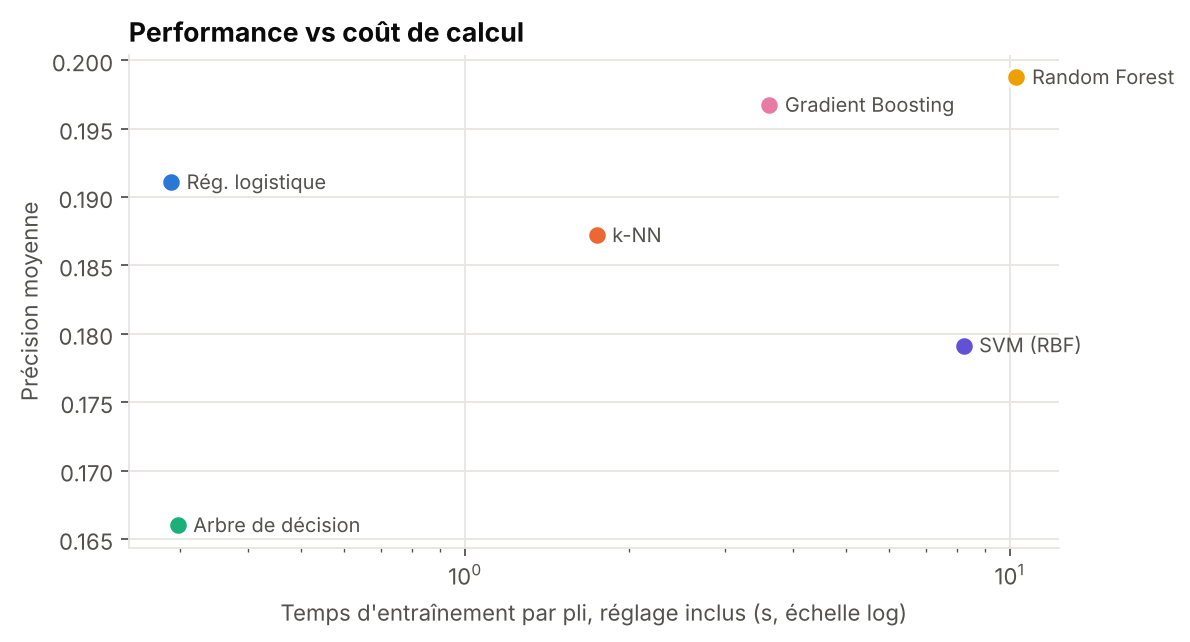

In [28]:
show('12_performance_vs_temps.png')

In [29]:
pd.read_csv(RES + 'best_params.csv')

,features,model,best_params
0,FWI seul,Indice FWI officiel seul,-
1,meteo seule,Arbre de décision,"{'max_depth': 3, 'min_samples_leaf': 50}"
2,meteo seule,Baseline (au hasard),-
3,meteo seule,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 3}"
4,meteo seule,Random Forest,"{'max_depth': 6, 'min_samples_leaf': 20}"
5,meteo seule,Régression logistique,{'C': 0.01}
6,meteo seule,SVM (noyau RBF),"{'C': 1, 'gamma': 'scale'}"
7,meteo seule,k-NN,"{'n_neighbors': 101, 'weights': 'uniform'}"
8,meteo+FWI,Arbre de décision,"{'max_depth': 5, 'min_samples_leaf': 50}"
9,meteo+FWI,Baseline (au hasard),-


## 9. Conclusion

| Critère | Choix | Pourquoi |
|---|---|---|
| Meilleur score | **Random Forest** | meilleure précision moyenne dans les deux scénarios |
| Meilleur rapport simplicité / score | **Régression logistique** | à égalité statistique, 35× plus rapide, interprétable |
| À éviter | Arbre seul, k-NN sans pondération | trop de variance ; aucune alerte au seuil par défaut |

- Prédire un feu à partir de la météo est **difficile** : le meilleur modèle est ≈ 1,9× meilleur que le hasard. La météo dit quand
  la forêt est prête à brûler, pas quand l'étincelle arrive (causes humaines).
- Les familles d'algorithmes sont **proches** ; la **méthode d'évaluation** (plis groupés par année, bonne métrique) compte autant
  que le choix du modèle.
- Sur des étés futurs, les modèles gardent un avantage alors que l'indice FWI seul tombe presque au niveau du hasard.

**Limites :** petits feux invisibles, brûlages agricoles possibles, météo de réanalyse (≈ 25 km), causes humaines absentes.